# 05 · Table 1 y gráficos del pitch

**Responsable:** Magno Luque · **Proyecto:** YAWAR (Hackathon FACI 2026, UPCH)

## Para qué sirve este cuaderno
Es el cuaderno que **entrega** el trabajo de análisis al resto del equipo. Toma las cifras ya calculadas y validadas (cuadernos 03 y 04) y produce:

1. **Table 1:** cómo es la población de niños de 6 a 35 meses en 2024 y en 2025, y cuánto cambió cada indicador (para la ficha técnica).
2. **Cuatro gráficos para el pitch** (archivos PNG en `analisis/graficos/`), cada uno con su título-conclusión y su fuente.
3. **Dos archivos de entrega**: uno para **Camilla** (cifras por departamento y región, para los mapas) y otro para **Gian** (proporciones por departamento, para el padrón simulado).
4. **Frases listas para usar**, con las cifras ya insertadas, y una lista de **frases que no se pueden decir**.

> **Regla de oro del proyecto:** toda cifra dice si está ponderada, de qué año y de qué edades. Aquí todo es **ponderado**, de **niños de 6 a 35 meses**, salvo que se diga otra cosa. Los archivos que se generan contienen solo porcentajes (no datos de personas), por lo que **sí pueden subirse al repositorio**.

## Cómo leerlo
Se ejecuta de arriba abajo, con la carpeta `analisis/` como directorio de trabajo. Requiere haber ejecutado antes los cuadernos 03 y 04 (leen sus archivos).

In [1]:
import sys
sys.path.insert(0, ".")

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import graficos as g
from rutas import RAIZ
from encuestas import Diseno, diferencias

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)

CARPETA = RAIZ / "datos_procesados"
RES = RAIZ / "analisis" / "resultados"
DOCS = RAIZ / "docs"
assert (RES / "cifras_ponderadas.csv").exists(), "Falta cifras_ponderadas.csv. Ejecuta primero el cuaderno 04."
assert (CARPETA / "tabla_nino_2025.csv").exists(), "Falta la tabla del niño. Ejecuta primero el cuaderno 03."

tablas = {a: pd.read_csv(CARPETA / f"tabla_nino_{a}.csv", low_memory=False) for a in (2024, 2025)}


def leer_resultados(archivo):
    # Lee un CSV de resultados y deja los nombres de columna que usa el estimador.
    d = pd.read_csv(RES / archivo)
    d = d.rename(columns={"estimacion_pct": "estimacion", "ic95_inf_pct": "ic_inf", "ic95_sup_pct": "ic_sup",
                          "error_estandar_pp": "se", "n_ninos_sin_ponderar": "n"})
    d["fiabilidad"] = d["fiabilidad"].fillna("")
    return d


cifras = leer_resultados("cifras_ponderadas.csv")
razones = leer_resultados("razones_no_consumo_sin_G.csv")

N_REC = "Recibió hierro del MINSA (12 meses)"
N_TOMO = "Tomó hierro en los últimos 7 días (todos los niños)"
N_ENTRE = "Tomó hierro en los últimos 7 días (entre los que recibieron)"
N_NO = "Recibió hierro y NO lo tomó la última semana (% de todos los niños)"
N_AN1 = "Anemia, criterio RM 363-2022-MINSA"
N_AN2 = "Anemia, criterio OMS 2024 / RM 251-2024-MINSA"
INDICADORES = [N_REC, N_TOMO, N_ENTRE, N_NO, N_AN1, N_AN2]
faltan = [n for n in INDICADORES if n not in set(cifras["indicador"])]
assert not faltan, f"Indicadores que no están en cifras_ponderadas.csv: {faltan}"
print("Cifras leídas:", len(cifras), "filas;", "razones:", len(razones), "filas.")
print("Años:", sorted(cifras['año'].unique()), "· ponderada:", cifras['ponderada'].unique(), "· universo:", cifras['universo'].unique())

Cifras leídas: 404 filas; razones: 630 filas.
Años: [np.int64(2024), np.int64(2025)] · ponderada: ['sí'] · universo: ['Niños de 6 a 35 meses']


## 1. Table 1
**Parte A (características):** qué porcentaje de los niños de 6 a 35 meses cae en cada categoría de edad, área, región natural y altitud, en cada año. Se calcula con la tabla del niño y el **factor mujer**, con el mismo estimador del cuaderno 04 (intervalos del 95 %).

**Parte B (indicadores):** las cifras del cuaderno 04, en el total nacional.

La última columna es el cambio 2025 − 2024 en puntos porcentuales (pp), con su intervalo del 95 %. **Lectura:** si el intervalo incluye el 0, no se puede distinguir de "no cambió". Supuesto: los dos años son independientes (conservador, ver cuaderno 04).

In [2]:
BANDAS_ALTITUD = ["menos de 1 000 m", "1 000 a 2 499 m", "2 500 m o más"]
for d in tablas.values():
    d["banda_altitud"] = pd.cut(d["altitud_msnm"], [-1, 999, 2499, 6000], labels=BANDAS_ALTITUD).astype(object)

VARIABLES = [
    ("Edad (meses)", "banda_edad", ["6-11", "12-23", "24-35"]),
    ("Área", "area", ["Urbano", "Rural"]),
    ("Región natural", "region_natural", ["Lima Metropolitana", "Resto Costa", "Sierra", "Selva"]),
    ("Altitud del conglomerado", "banda_altitud", BANDAS_ALTITUD),
]

diseno = {a: Diseno(d, "factor_expansion_crudo") for a, d in tablas.items()}
filas = []
for a, d in tablas.items():
    u = d["en_universo_6_35"].to_numpy(bool)
    for variable, col, categorias in VARIABLES:
        assert d.loc[u, col].notna().all(), f"{a}: hay niños sin {col}"
        for c in categorias:
            r = diseno[a].proporcion((d[col] == c).astype(float), u)
            r["n"] = int(((d[col] == c) & u).sum())     # niños de la encuesta en esa categoría
            filas.append({"indicador": "Composición", "grupo_tipo": variable, "grupo": c, "año": a, **r})
composicion = pd.DataFrame(filas)

# Control: dentro de cada variable, los porcentajes deben sumar 100
chk = composicion.groupby(["año", "grupo_tipo"])["estimacion"].sum().round(6)
assert (chk == 100).all(), chk
print("Control: los porcentajes de cada variable suman 100 en los dos años.")
print(composicion.groupby(["año", "grupo_tipo"])["n"].sum().unstack(0).to_string())

Control: los porcentajes de cada variable suman 100 en los dos años.
año                        2024  2025
grupo_tipo                           
Altitud del conglomerado  10197  9589
Edad (meses)              10197  9589
Región natural            10197  9589
Área                      10197  9589


In [3]:
def armar_tabla(largo, bloque):
    # Une 2024 y 2025 de cada fila y calcula el cambio con su intervalo.
    dif = diferencias(largo)
    filas = []
    for (ind, tipo, grupo), s in largo.groupby(["indicador", "grupo_tipo", "grupo"], sort=False):
        a, b = s[s["año"] == 2024].iloc[0], s[s["año"] == 2025].iloc[0]
        c = dif[(dif["indicador"] == ind) & (dif["grupo_tipo"] == tipo) & (dif["grupo"] == grupo)].iloc[0]
        filas.append({
            "bloque": bloque, "indicador": ind, "variable": tipo, "categoria": grupo,
            "pct_2024": a["estimacion"], "ic95_2024_inf": a["ic_inf"], "ic95_2024_sup": a["ic_sup"], "n_2024": int(a["n"]),
            "pct_2025": b["estimacion"], "ic95_2025_inf": b["ic_inf"], "ic95_2025_sup": b["ic_sup"], "n_2025": int(b["n"]),
            "cambio_pp": c["cambio_pp"], "cambio_ic95_inf": c["ic_inf"], "cambio_ic95_sup": c["ic_sup"],
            "cambio_distinto_de_0": c["distinto_de_0"],
        })
    return pd.DataFrame(filas)


def fmt(t):
    # Tabla para leer: cada celda como  % (IC95).
    out = pd.DataFrame({
        "variable": t["variable"], "categoría": t["categoria"],
        "2024: % (IC 95 %)": [f"{r.pct_2024:.1f} ({r.ic95_2024_inf:.1f}–{r.ic95_2024_sup:.1f})" for r in t.itertuples()],
        "2025: % (IC 95 %)": [f"{r.pct_2025:.1f} ({r.ic95_2025_inf:.1f}–{r.ic95_2025_sup:.1f})" for r in t.itertuples()],
        "cambio, pp (IC 95 %)": [f"{r.cambio_pp:+.1f} ({r.cambio_ic95_inf:+.1f} a {r.cambio_ic95_sup:+.1f})" for r in t.itertuples()],
        "¿distinto de 0?": t["cambio_distinto_de_0"],
        "n 2024": t["n_2024"], "n 2025": t["n_2025"],
    })
    return out


tabla_A = armar_tabla(composicion, "A. Características (% de niños de 6 a 35 meses)")
tot = cifras[(cifras["grupo_tipo"] == "Total") & cifras["indicador"].isin(INDICADORES)].copy()
tot["indicador"] = pd.Categorical(tot["indicador"], INDICADORES, ordered=True)
tot = tot.sort_values(["año", "indicador"]).assign(indicador=lambda d: d["indicador"].astype(str))
tabla_B = armar_tabla(tot, "B. Indicadores, total nacional (%)")
tabla_B["variable"] = tabla_B["indicador"]
tabla_B["categoria"] = "Total"

print("=== A. Características (ponderado, factor mujer) ===")
print(fmt(tabla_A).to_string(index=False))
print()
print("=== B. Indicadores, total nacional (ponderado) ===")
print(fmt(tabla_B).to_string(index=False))

=== A. Características (ponderado, factor mujer) ===
                variable          categoría 2024: % (IC 95 %) 2025: % (IC 95 %) cambio, pp (IC 95 %) ¿distinto de 0?  n 2024  n 2025
            Edad (meses)               6-11  20.4 (19.4–21.5)  21.1 (20.0–22.2)   +0.6 (-0.9 a +2.1)              no    2104    1986
            Edad (meses)              12-23  39.8 (38.6–41.0)  39.8 (38.4–41.2)   -0.0 (-1.8 a +1.8)              no    4063    3810
            Edad (meses)              24-35  39.8 (38.5–41.0)  39.2 (37.8–40.5)   -0.6 (-2.5 a +1.2)              no    4030    3793
                    Área             Urbano  72.3 (71.2–73.3)  74.6 (73.5–75.7)   +2.4 (+0.8 a +3.9)              sí    7070    6940
                    Área              Rural  27.7 (26.7–28.8)  25.4 (24.3–26.5)   -2.4 (-3.9 a -0.8)              sí    3127    2649
          Región natural Lima Metropolitana  24.0 (22.8–25.3)  28.1 (26.7–29.6)   +4.1 (+2.2 a +6.1)              sí    1095    1164
          Región

### Tabla 1b: indicadores por edad
Los mismos indicadores por grupo de edad. Sirve para ver **dónde** se concentra el problema y **dónde** hubo cambio.

In [4]:
por_edad = cifras[(cifras["grupo_tipo"] == "Edad (meses)") & cifras["indicador"].isin(INDICADORES)].copy()
por_edad["indicador"] = pd.Categorical(por_edad["indicador"], INDICADORES, ordered=True)
por_edad["_o"] = por_edad["grupo"].map({"6-11": 0, "12-23": 1, "24-35": 2})
por_edad = por_edad.sort_values(["indicador", "_o", "año"]).drop(columns="_o").assign(indicador=lambda d: d["indicador"].astype(str))
tabla_C = armar_tabla(por_edad, "C. Indicadores por edad (%)")
vista = fmt(tabla_C)
vista.insert(0, "indicador", tabla_C["indicador"].str.slice(0, 52))
print(vista.drop(columns="variable").to_string(index=False))

# Guardar Table 1 completa (solo porcentajes: se puede subir al repositorio)
table1 = pd.concat([tabla_A, tabla_B, tabla_C], ignore_index=True)
for c in table1.columns:
    if c.startswith(("pct", "ic95", "cambio_pp", "cambio_ic")):
        table1[c] = table1[c].round(2)
table1["ponderada"] = "sí"
table1["universo"] = "Niños de 6 a 35 meses"
table1.to_csv(RES / "tabla1_2024_2025.csv", index=False, encoding="utf-8-sig")
print("\nGuardado: analisis/resultados/tabla1_2024_2025.csv", f"({len(table1)} filas)")

                                           indicador categoría 2024: % (IC 95 %) 2025: % (IC 95 %) cambio, pp (IC 95 %) ¿distinto de 0?  n 2024  n 2025
                 Recibió hierro del MINSA (12 meses)      6-11  81.8 (79.2–84.1)  79.1 (76.4–81.6)   -2.7 (-6.2 a +0.9)              no    2085    1977
                 Recibió hierro del MINSA (12 meses)     12-23  77.3 (75.5–79.1)  77.6 (75.8–79.4)   +0.3 (-2.2 a +2.8)              no    4014    3774
                 Recibió hierro del MINSA (12 meses)     24-35  58.3 (56.2–60.3)  62.4 (60.2–64.5)   +4.1 (+1.2 a +7.0)              sí    3980    3753
 Tomó hierro en los últimos 7 días (todos los niños)      6-11  65.4 (62.7–68.1)  65.5 (62.6–68.2)   +0.0 (-3.8 a +3.9)              no    2086    1978
 Tomó hierro en los últimos 7 días (todos los niños)     12-23  30.9 (29.1–32.9)  38.1 (36.2–40.1)  +7.2 (+4.4 a +10.0)              sí    4013    3773
 Tomó hierro en los últimos 7 días (todos los niños)     24-35  20.3 (18.8–21.9)  24.9 (

### Table 1 en formato para pegar en la ficha
Se genera un archivo de texto (Markdown) que se puede abrir en cualquier editor y pegar en Word; la nota al pie dice cómo se calculó.

In [5]:
def a_markdown(t, titulo):
    v = fmt(t).drop(columns=["variable"]) if titulo[0] != "B" else fmt(t).drop(columns=["categoría"]).rename(columns={"variable": "indicador"})
    lineas = [f"### {titulo}", "", "| " + " | ".join(v.columns) + " |", "|" + "|".join(["---"] * len(v.columns)) + "|"]
    for r in v.itertuples(index=False):
        lineas.append("| " + " | ".join(str(x).replace(".", ",") if isinstance(x, str) else str(x) for x in r) + " |")
    return lineas


md_lineas = ["# Table 1: niños de 6 a 35 meses, ENDES 2024 y 2025", "",
             "_Generado por `analisis/05_table1_y_graficos.ipynb`. No editar a mano: se regenera al ejecutar el cuaderno._", ""]
for t, titulo in [(tabla_A, "A. Características (% de niños)"), (tabla_B, "B. Indicadores, total nacional (%)"), (tabla_C, "C. Indicadores por edad (%)")]:
    md_lineas += a_markdown(t, titulo) + [""]
md_lineas += [
    "**Notas.**",
    "- Cifras **ponderadas**, de niños de **6 a 35 meses** (edad calculada como fecha de entrevista − fecha de nacimiento). Entre paréntesis, intervalo de confianza del 95 %.",
    "- Estimador: linealización de Taylor con estratos y conglomerados (cuaderno 04). IC en escala logit con t de Student. Se valida contra cifras de INEI y contra jackknife.",
    "- Factor de expansión: **mujer** para características y para hierro; **hogar** para anemia (según la ficha técnica de ENDES). La ficha no fija el factor del hierro; con el factor hogar \"recibió\" cambia hasta 1,3 pp.",
    "- Cambio = 2025 − 2024, en puntos porcentuales. Intervalo calculado suponiendo muestras independientes (conservador, ya que ~64 % de los niños de 2025 vive en conglomerados que también estaban en 2024).",
    "- \"Tomó hierro\" se refiere a los **últimos 7 días**; \"recibió\", a los **últimos 12 meses**. \"No lo tomó\" **no equivale a abandono**.",
    "- Anemia: solo niños con hemoglobina medida; dos criterios oficiales (RM 363-2022-MINSA y OMS 2024 / RM 251-2024-MINSA).",
    "- Fuente: INEI, ENDES 2024 y 2025, microdatos públicos. Cálculo propio, equipo YAWAR.",
]
DOCS.mkdir(exist_ok=True)
(DOCS / "tabla1_2024_2025.md").write_text("\n".join(md_lineas) + "\n", encoding="utf-8")
print("Guardado: docs/tabla1_2024_2025.md")

Guardado: docs/tabla1_2024_2025.md


## 2. Gráficos para el pitch
Cuatro gráficos, uno por mensaje. Cada uno:
- lleva un **título que dice la conclusión** (con las cifras tomadas de los resultados, no escritas a mano),
- indica en el subtítulo y en el pie **qué se mide, en quién, en qué año y si está ponderado**,
- usa los mismos colores en todo el proyecto: **2024 azul, 2025 naranja**; **recibió hierro violeta, tomó hierro verde azulado**,
- se guarda como PNG en `analisis/graficos/`, junto con una tabla de los datos graficados (`datos_graficos_pitch.csv`) por si hace falta rehacerlos o leerlos sin la imagen.

Guardado: analisis/graficos/g1_recibir_no_es_tomar_2025.png


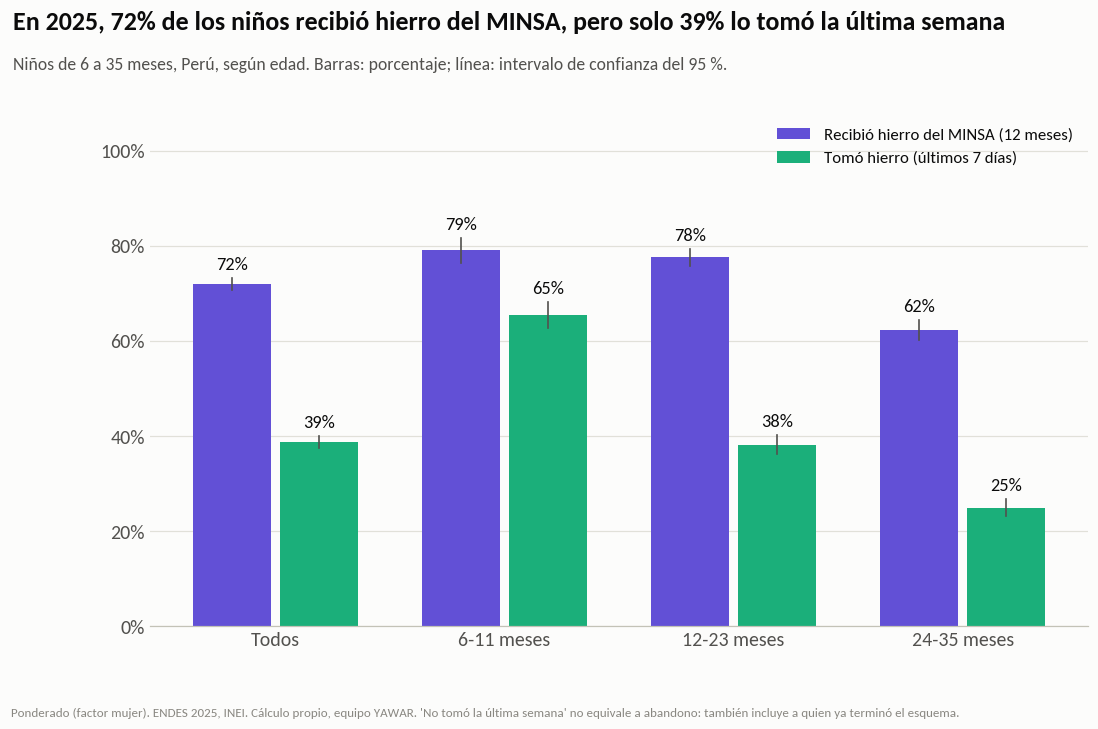

In [6]:
datos_pitch = []   # tabla gemela: todo lo que se dibuja queda también en números


def anotar(grafico, serie, grupo, r):
    datos_pitch.append({"grafico": grafico, "serie": serie, "grupo": grupo, "porcentaje": round(float(r["estimacion"]), 2),
                        "ic95_inf": round(float(r["ic_inf"]), 2), "ic95_sup": round(float(r["ic_sup"]), 2), "n_ninos": int(r["n"])})


GX = [("Total", "Total", "Todos"), ("Edad (meses)", "6-11", "6-11 meses"), ("Edad (meses)", "12-23", "12-23 meses"), ("Edad (meses)", "24-35", "24-35 meses")]

# ---- Gráfico 1: recibir no es tomar (2025) ----
rec, tom = g.fila(cifras, N_REC, "Total", "Total", 2025), g.fila(cifras, N_TOMO, "Total", "Total", 2025)
with plt.rc_context({"font.size": 13}):
    fig, ax = plt.subplots(figsize=(11, 6.4))
    for ind, color, desp, nombre in ((N_REC, g.COLOR_RECIBIO, -0.19, "Recibió hierro del MINSA (últimos 12 meses)"), (N_TOMO, g.COLOR_TOMO, 0.19, "Tomó hierro (últimos 7 días)")):
        for i, (tipo, grupo, _) in enumerate(GX):
            r = g.fila(cifras, ind, tipo, grupo, 2025)
            g.barra_v(ax, i + desp, r["estimacion"], r["ic_inf"], r["ic_sup"], color, ancho=0.34)
            ax.text(i + desp, r["ic_sup"] + 1.8, f"{r['estimacion']:.0f}%", ha="center", fontsize=12, color=g.TINTA)
            anotar("G1 recibir no es tomar (2025)", nombre, grupo, r)
    ax.set_xticks(range(len(GX)))
    ax.set_xticklabels([x[2] for x in GX])
    ax.set_ylim(0, 108)
    ax.yaxis.set_major_formatter(lambda v, p: f"{v:.0f}%")
    g.rejilla(ax, "y")
    g.leyenda(ax, [("Recibió hierro del MINSA (12 meses)", g.COLOR_RECIBIO), ("Tomó hierro (últimos 7 días)", g.COLOR_TOMO)], loc="upper right", fontsize=11)
    g.titulos(fig, f"En 2025, {rec['estimacion']:.0f}% de los niños recibió hierro del MINSA, pero solo {tom['estimacion']:.0f}% lo tomó la última semana",
              "Niños de 6 a 35 meses, Perú, según edad. Barras: porcentaje; línea: intervalo de confianza del 95 %.")
    g.pie(fig, "Ponderado (factor mujer). ENDES 2025, INEI. Cálculo propio, equipo YAWAR. 'No tomó la última semana' no equivale a abandono: también incluye a quien ya terminó el esquema.", y=-0.02)
    fig.subplots_adjust(top=0.84)
    ruta = g.guardar(fig, "g1_recibir_no_es_tomar_2025")
    plt.show()
print("Guardado:", ruta.relative_to(RAIZ))

Guardado: analisis/graficos/g2_razones_no_consumo_2025.png


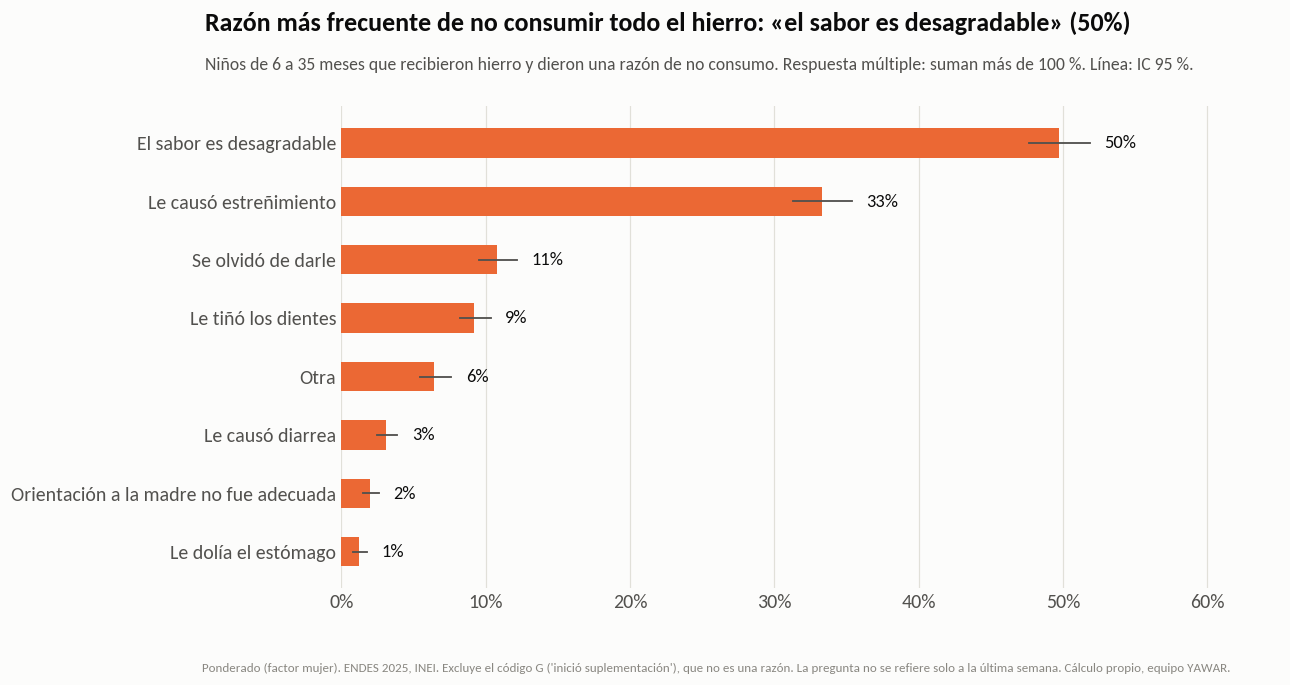

In [7]:
# ---- Gráfico 2: razones de no consumo (2025) ----
rz = razones[(razones["grupo_tipo"] == "Total") & (razones["año"] == 2025) & (~razones["indicador"].str.startswith("Respondieron"))].sort_values("estimacion")
assert len(rz) == 8, len(rz)
top1 = rz.sort_values("estimacion", ascending=False).iloc[0]
with plt.rc_context({"font.size": 13}):
    fig, ax = plt.subplots(figsize=(11, 6.0))
    y = np.arange(len(rz))
    for yi, (_, r) in zip(y, rz.iterrows()):
        ax.barh(yi, r["estimacion"], height=0.5, color=g.COLOR_ANIO[2025], zorder=2)
        ax.plot([r["ic_inf"], r["ic_sup"]], [yi, yi], color=g.TINTA2, linewidth=1.2, zorder=3)
        ax.text(r["ic_sup"] + 1.0, yi, f"{r['estimacion']:.0f}%", va="center", fontsize=12, color=g.TINTA)
        anotar("G2 razones de no consumo (2025)", "Razón (respuesta múltiple)", r["indicador"], r)
    ax.set_yticks(y)
    ax.set_yticklabels(rz["indicador"])
    ax.set_xlim(0, 65)
    ax.xaxis.set_major_formatter(lambda v, p: f"{v:.0f}%")
    g.rejilla(ax, "x")
    g.titulos(fig, f"Razón más frecuente de no consumir todo el hierro: «{top1['indicador'].lower()}» ({top1['estimacion']:.0f}%)",
              "Niños de 6 a 35 meses que recibieron hierro y dieron una razón de no consumo. Respuesta múltiple: suman más de 100 %. Línea: IC 95 %.")
    g.pie(fig, "Ponderado (factor mujer). ENDES 2025, INEI. Excluye el código G ('inició suplementación'), que no es una razón. La pregunta no se refiere solo a la última semana. Cálculo propio, equipo YAWAR.", y=-0.02)
    fig.subplots_adjust(top=0.84)
    ruta = g.guardar(fig, "g2_razones_no_consumo_2025")
    plt.show()
print("Guardado:", ruta.relative_to(RAIZ))

Guardado: analisis/graficos/g3_tomo_hierro_por_departamento_2025.png


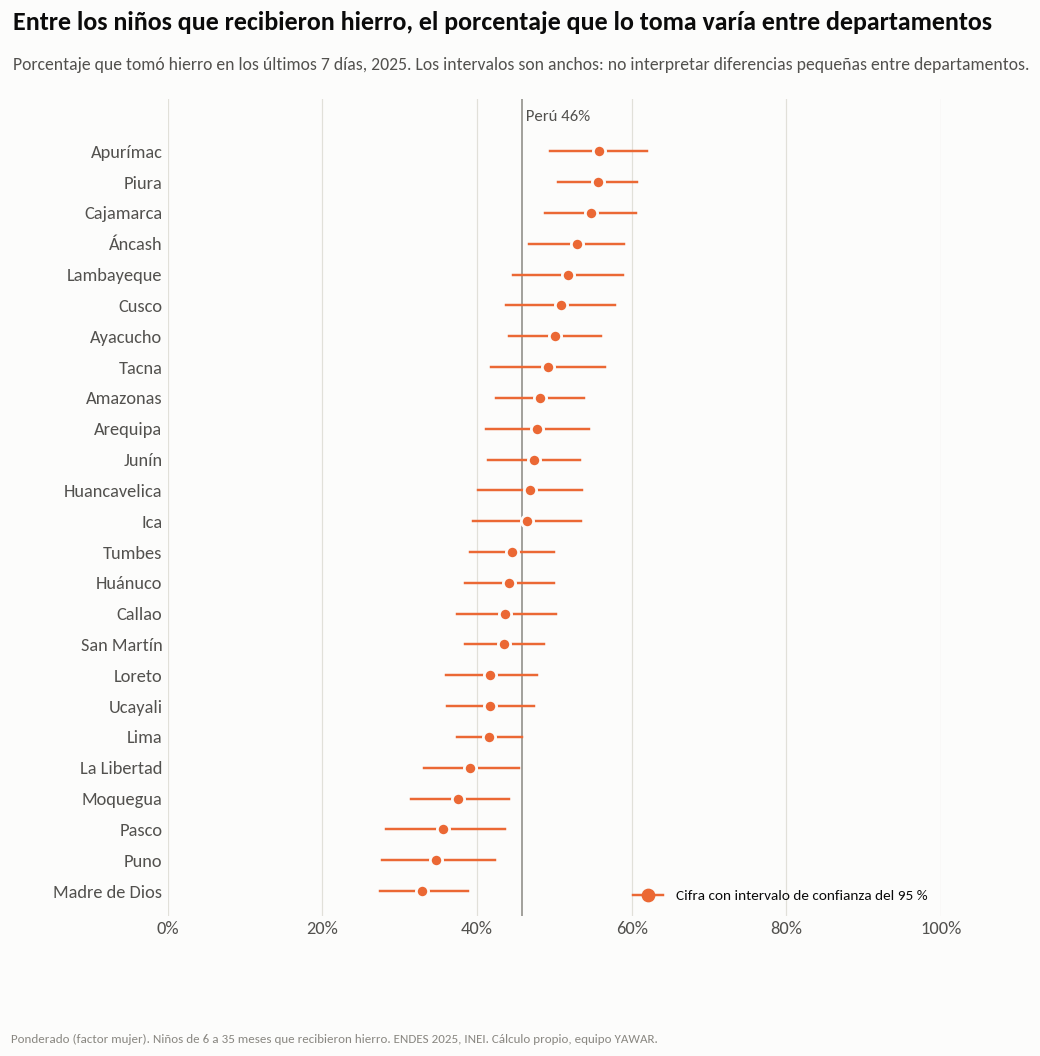

In [8]:
# ---- Gráfico 3: tomar el hierro recibido, por departamento (2025) ----
dep = cifras[(cifras["indicador"] == N_ENTRE) & (cifras["grupo_tipo"] == "Departamento") & (cifras["año"] == 2025)].sort_values("estimacion")
nac = g.fila(cifras, N_ENTRE, "Total", "Total", 2025)
assert len(dep) == 25, len(dep)
with plt.rc_context({"font.size": 12}):
    fig, ax = plt.subplots(figsize=(9.5, 9.4))
    y = np.arange(len(dep))
    for yi, (_, r) in zip(y, dep.iterrows()):
        cauteloso = r["fiabilidad"] != ""
        ax.plot([r["ic_inf"], r["ic_sup"]], [yi, yi], color=g.COLOR_ANIO[2025], linewidth=1.6, zorder=2)
        ax.plot([r["estimacion"]], [yi], "o", markersize=8, color=g.COLOR_ANIO[2025], markeredgecolor=g.COLOR_ANIO[2025] if cauteloso else g.SUPERFICIE,
                markerfacecolor=g.SUPERFICIE if cauteloso else g.COLOR_ANIO[2025], markeredgewidth=1.8, zorder=3)
        anotar("G3 tomó entre los que recibieron, por departamento (2025)", "2025", r["grupo"], r)
    ax.axvline(nac["estimacion"], color=g.APAGADO, linewidth=1, zorder=1)
    ax.text(nac["estimacion"], len(dep) - 0.1, f" Perú {nac['estimacion']:.0f}%", fontsize=11, color=g.TINTA2, va="bottom")
    ax.set_yticks(y)
    ax.set_yticklabels(dep["grupo"])
    ax.set_ylim(-0.8, len(dep) + 0.7)
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(lambda v, p: f"{v:.0f}%")
    g.rejilla(ax, "x")
    from matplotlib.lines import Line2D
    asas = [Line2D([], [], marker="o", color=g.COLOR_ANIO[2025], linewidth=1.6, markersize=8, label="Cifra con intervalo de confianza del 95 %")]
    if (dep["fiabilidad"] != "").any():
        asas.append(Line2D([], [], marker="o", linestyle="", markerfacecolor=g.SUPERFICIE, markeredgecolor=g.COLOR_ANIO[2025], markeredgewidth=1.8, markersize=8, label="Poco precisa (CV mayor a 15 %)"))
    ax.legend(handles=asas, loc="lower right", fontsize=10)
    g.titulos(fig, "Entre los niños que recibieron hierro, el porcentaje que lo toma varía entre departamentos",
              "Porcentaje que tomó hierro en los últimos 7 días, 2025. Los intervalos son anchos: no interpretar diferencias pequeñas entre departamentos.")
    g.pie(fig, "Ponderado (factor mujer). Niños de 6 a 35 meses que recibieron hierro. ENDES 2025, INEI. Cálculo propio, equipo YAWAR.", y=-0.015)
    fig.subplots_adjust(top=0.90, left=0.16)
    ruta = g.guardar(fig, "g3_tomo_hierro_por_departamento_2025")
    plt.show()
print("Guardado:", ruta.relative_to(RAIZ))

Guardado: analisis/graficos/g4_anemia_2024_2025.png
Guardado: analisis/graficos/datos_graficos_pitch.csv (49 filas)


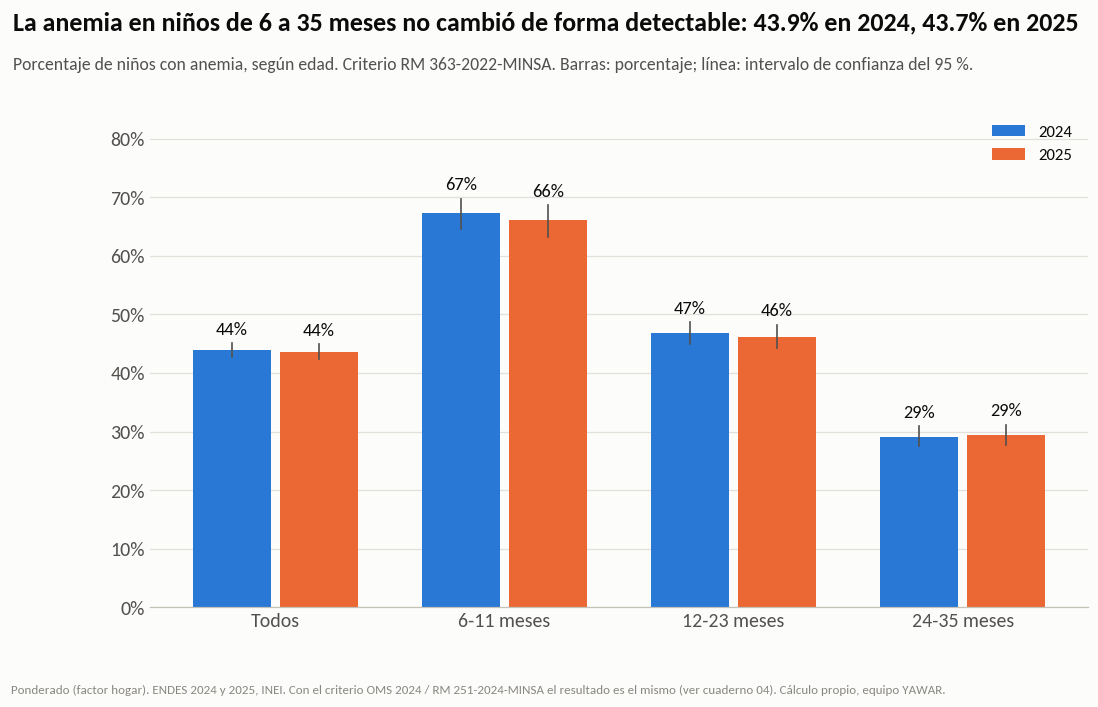

In [9]:
# ---- Gráfico 4: anemia 2024 vs 2025 (criterio MINSA 2022) ----
a24, a25 = g.fila(cifras, N_AN1, "Total", "Total", 2024), g.fila(cifras, N_AN1, "Total", "Total", 2025)
with plt.rc_context({"font.size": 13}):
    fig, ax = plt.subplots(figsize=(11, 6.2))
    for anio, desp in ((2024, -0.19), (2025, 0.19)):
        for i, (tipo, grupo, _) in enumerate(GX):
            r = g.fila(cifras, N_AN1, tipo, grupo, anio)
            g.barra_v(ax, i + desp, r["estimacion"], r["ic_inf"], r["ic_sup"], g.COLOR_ANIO[anio], ancho=0.34)
            ax.text(i + desp, r["ic_sup"] + 1.5, f"{r['estimacion']:.0f}%", ha="center", fontsize=12, color=g.TINTA)
            anotar("G4 anemia 2024 vs 2025 (criterio MINSA 2022)", str(anio), grupo, r)
    ax.set_xticks(range(len(GX)))
    ax.set_xticklabels([x[2] for x in GX])
    ax.set_ylim(0, 85)
    ax.yaxis.set_major_formatter(lambda v, p: f"{v:.0f}%")
    g.rejilla(ax, "y")
    g.leyenda(ax, [("2024", g.COLOR_ANIO[2024]), ("2025", g.COLOR_ANIO[2025])], loc="upper right", fontsize=11)
    g.titulos(fig, f"La anemia en niños de 6 a 35 meses no cambió de forma detectable: {a24['estimacion']:.1f}% en 2024, {a25['estimacion']:.1f}% en 2025",
              "Porcentaje de niños con anemia, según edad. Criterio RM 363-2022-MINSA. Barras: porcentaje; línea: intervalo de confianza del 95 %.")
    g.pie(fig, "Ponderado (factor hogar). ENDES 2024 y 2025, INEI. Con el criterio OMS 2024 / RM 251-2024-MINSA el resultado es el mismo (ver cuaderno 04). Cálculo propio, equipo YAWAR.", y=-0.02)
    fig.subplots_adjust(top=0.84)
    ruta = g.guardar(fig, "g4_anemia_2024_2025")
    plt.show()
print("Guardado:", ruta.relative_to(RAIZ))

pd.DataFrame(datos_pitch).to_csv(g.CARPETA / "datos_graficos_pitch.csv", index=False, encoding="utf-8-sig")
print("Guardado: analisis/graficos/datos_graficos_pitch.csv", f"({len(datos_pitch)} filas)")

## 3. Archivos de entrega para el equipo
Estos dos archivos son la forma en que Camilla y Gian reciben **las cifras reales de ENDES**. No contienen datos de personas.

### Para Camilla (mapas y visualización)
Una fila por **año × departamento (o región natural, o total) × indicador**. Columnas: `anio`, `nivel` (Departamento, Región natural o Total), `lugar`, `indicador`, `porcentaje`, `ic95_inf`, `ic95_sup`, `n_ninos` (niños de la encuesta, sin ponderar), `fiabilidad` (vacía si la cifra es precisa; si no, dice por qué usarla con cautela).

**Cuidado al mapear:** con 200 a 450 niños por departamento, los intervalos son anchos. Conviene mostrar el intervalo o agrupar en tramos amplios, y no rankear departamentos vecinos.

In [10]:
IND_CAMILLA = [N_REC, N_TOMO, N_ENTRE, N_NO, N_AN1, N_AN2]
cam = cifras[cifras["grupo_tipo"].isin(["Departamento", "Región natural", "Total"]) & cifras["indicador"].isin(IND_CAMILLA)].copy()
cam = cam.rename(columns={"año": "anio", "grupo_tipo": "nivel", "grupo": "lugar", "estimacion": "porcentaje", "ic_inf": "ic95_inf", "ic_sup": "ic95_sup", "n": "n_ninos"})
cam["indicador"] = pd.Categorical(cam["indicador"], IND_CAMILLA, ordered=True)
cam["nivel"] = pd.Categorical(cam["nivel"], ["Total", "Región natural", "Departamento"], ordered=True)
cam = cam.sort_values(["indicador", "anio", "nivel", "lugar"])[["anio", "nivel", "lugar", "indicador", "porcentaje", "ic95_inf", "ic95_sup", "n_ninos", "fiabilidad"]]
cam["indicador"] = cam["indicador"].astype(str)
cam["nivel"] = cam["nivel"].astype(str)
cam["porcentaje"], cam["ic95_inf"], cam["ic95_sup"] = cam["porcentaje"].round(1), cam["ic95_inf"].round(1), cam["ic95_sup"].round(1)
cam["ponderada"] = "sí"
cam["universo"] = "Niños de 6 a 35 meses (anemia: con hemoglobina medida)"
cam.to_csv(RES / "para_camilla_departamentos.csv", index=False, encoding="utf-8-sig")
print("Guardado: analisis/resultados/para_camilla_departamentos.csv", f"({len(cam)} filas)")
print("Departamentos:", cam.loc[cam['nivel'] == 'Departamento', 'lugar'].nunique(), "· Regiones naturales:", cam.loc[cam['nivel'] == 'Región natural', 'lugar'].nunique())
print()
print(cam[(cam["indicador"] == N_ENTRE) & (cam["nivel"] == "Departamento") & (cam["anio"] == 2025)].head(6).to_string(index=False))
print("\nCifras con baja precisión (para que Camilla las trate con cautela):")
print(cam[cam["nivel"] == "Departamento"].groupby("fiabilidad").size().rename("filas").to_string())

Guardado: analisis/resultados/para_camilla_departamentos.csv (344 filas)
Departamentos: 25 · Regiones naturales: 4

 anio        nivel     lugar                                                    indicador  porcentaje  ic95_inf  ic95_sup  n_ninos fiabilidad ponderada                                               universo
 2025 Departamento  Amazonas Tomó hierro en los últimos 7 días (entre los que recibieron)        48.1      42.5      53.8      350                   sí Niños de 6 a 35 meses (anemia: con hemoglobina medida)
 2025 Departamento  Apurímac Tomó hierro en los últimos 7 días (entre los que recibieron)        55.8      49.5      62.0      268                   sí Niños de 6 a 35 meses (anemia: con hemoglobina medida)
 2025 Departamento  Arequipa Tomó hierro en los últimos 7 días (entre los que recibieron)        47.8      41.2      54.5      208                   sí Niños de 6 a 35 meses (anemia: con hemoglobina medida)
 2025 Departamento  Ayacucho Tomó hierro en los últimos 

### Para Gian (padrón simulado)
Proporciones **ponderadas** de edad, área, región natural y altitud **dentro de cada departamento**, por año. Con ellas se puede generar un padrón simulado cuya composición se parezca a la real sin usar datos de personas. Una fila por **año × departamento × variable × categoría**; también hay filas del total nacional (`departamento = Perú`).

Las tasas de partida (recibió, tomó) por departamento están en el archivo de Camilla.

In [11]:
filas = []
for a, d in tablas.items():
    u = d["en_universo_6_35"].to_numpy(bool)
    lugares = [("Perú", np.ones(len(d), bool))] + [(dp, (d["departamento"] == dp).to_numpy()) for dp in sorted(d["departamento"].dropna().unique())]
    for lugar, m in lugares:
        for variable, col, categorias in VARIABLES:
            for c in categorias:
                r = diseno[a].proporcion((d[col] == c).astype(float), u & m)
                filas.append({"anio": a, "departamento": lugar, "variable": variable, "categoria": c,
                              "porcentaje": round(r["estimacion"], 2), "ic95_inf": round(r["ic_inf"], 2) if pd.notna(r["ic_inf"]) else np.nan,
                              "ic95_sup": round(r["ic_sup"], 2) if pd.notna(r["ic_sup"]) else np.nan, "n_ninos_departamento": r["n"]})
gian = pd.DataFrame(filas)
gian["ponderada"] = "sí"
gian["universo"] = "Niños de 6 a 35 meses"

# Control: dentro de cada año, lugar y variable, los porcentajes suman 100
sumas = gian.groupby(["anio", "departamento", "variable"])["porcentaje"].sum()
assert (sumas.sub(100).abs() < 0.1).all(), sumas[sumas.sub(100).abs() >= 0.1]
gian.to_csv(RES / "para_gian_proporciones_departamento.csv", index=False, encoding="utf-8-sig")
print("Guardado: analisis/resultados/para_gian_proporciones_departamento.csv", f"({len(gian)} filas)")
print("Control: los porcentajes de cada variable suman 100 en cada departamento y año.")
print(gian[(gian["departamento"] == "Puno") & (gian["anio"] == 2025)][["variable", "categoria", "porcentaje", "n_ninos_departamento"]].to_string(index=False))

Guardado: analisis/resultados/para_gian_proporciones_departamento.csv (624 filas)
Control: los porcentajes de cada variable suman 100 en cada departamento y año.
                variable          categoria  porcentaje  n_ninos_departamento
            Edad (meses)               6-11       18.32                   232
            Edad (meses)              12-23       39.61                   232
            Edad (meses)              24-35       42.07                   232
                    Área             Urbano       60.37                   232
                    Área              Rural       39.63                   232
          Región natural Lima Metropolitana        0.00                   232
          Región natural        Resto Costa        0.00                   232
          Región natural             Sierra       90.95                   232
          Región natural              Selva        9.05                   232
Altitud del conglomerado   menos de 1 000 m        2.50   

## 4. Frases listas para usar (cifras tomadas de los resultados)

In [12]:
d = lambda ind, a, tipo="Total", grupo="Total": g.fila(cifras, ind, tipo, grupo, a)
ic = lambda r: f"IC 95 %: {r['ic_inf']:.1f}–{r['ic_sup']:.1f}"
dif_tot = diferencias(cifras[(cifras["grupo_tipo"] == "Total") & cifras["indicador"].isin(INDICADORES)]).set_index("indicador")
r_rec, r_tom, r_ent, r_no, r_an = d(N_REC, 2025), d(N_TOMO, 2025), d(N_ENTRE, 2025), d(N_NO, 2025), d(N_AN1, 2025)
joven, mayor = d(N_ENTRE, 2025, "Edad (meses)", "6-11"), d(N_ENTRE, 2025, "Edad (meses)", "24-35")
cambio_tomo = dif_tot.loc[N_TOMO]
cambio_an = dif_tot.loc[N_AN1]

frases_ok = [
    f"En 2025, {r_rec['estimacion']:.0f} % de los niños peruanos de 6 a 35 meses recibió hierro del MINSA en los últimos 12 meses ({ic(r_rec)}), pero solo {r_tom['estimacion']:.0f} % lo tomó en los últimos 7 días ({ic(r_tom)}).",
    f"Entre los niños que sí recibieron hierro, {r_ent['estimacion']:.0f} % lo tomó la última semana; la cifra baja con la edad: {joven['estimacion']:.0f} % a los 6-11 meses y {mayor['estimacion']:.0f} % a los 24-35 meses.",
    f"La anemia en niños de 6 a 35 meses fue {d(N_AN1, 2024)['estimacion']:.1f} % en 2024 y {r_an['estimacion']:.1f} % en 2025 (criterio RM 363-2022-MINSA): la encuesta no detecta un cambio entre los dos años ({cambio_an['cambio_pp']:+.1f} pp; IC 95 %: {cambio_an['ic_inf']:+.1f} a {cambio_an['ic_sup']:+.1f}).",
    f"Entre 2024 y 2025 mejoró el consumo de hierro: el porcentaje de niños que lo tomó la última semana subió {cambio_tomo['cambio_pp']:.1f} puntos (IC 95 %: {cambio_tomo['ic_inf']:+.1f} a {cambio_tomo['ic_sup']:+.1f}). El problema persiste, pero no está empeorando.",
    f"{r_no['estimacion']:.0f} % de todos los niños de 6 a 35 meses recibió hierro y no lo tomó la última semana (2025).",
]
print("PUEDES DECIR (siempre con año, edades y 'ponderado' si te lo preguntan):")
for f in frases_ok:
    print(" •", re.sub(r"(\d)\.(\d)", r",", f))
print()
print("NO PUEDES DECIR:")
for f in [
    "'La herramienta reduce la anemia.' No hay ninguna medición del efecto de la herramienta; ENDES solo describe la situación actual.",
    "'La mitad de los niños abandona el hierro.' 'No tomó la última semana' incluye a quien ya terminó su esquema, no solo a quien abandonó.",
    "'El departamento X es peor que el Y.' Con 200 a 450 niños por departamento, los intervalos se superponen casi siempre.",
    "Cualquier cifra de INEI de 2025 como 'oficial': la de anemia 2025 que usé para validar viene de una nota de prensa; falta verificarla en la publicación de INEI.",
    "Totales de niños (por ejemplo, 'X mil niños'): solo calculamos porcentajes.",
]:
    print(" NO:", f)

PUEDES DECIR (siempre con año, edades y 'ponderado' si te lo preguntan):
 • En 2025, 72 % de los niños peruanos de 6 a 35 meses recibió hierro del MINSA en los últimos 12 meses (IC 95 %: 7,–7,), pero solo 39 % lo tomó en los últimos 7 días (IC 95 %: 3,–4,).
 • Entre los niños que sí recibieron hierro, 46 % lo tomó la última semana; la cifra baja con la edad: 70 % a los 6-11 meses y 34 % a los 24-35 meses.
 • La anemia en niños de 6 a 35 meses fue 4, % en 2024 y 4, % en 2025 (criterio RM 363-2022-MINSA): la encuesta no detecta un cambio entre los dos años (-, pp; IC 95 %: -, a +,).
 • Entre 2024 y 2025 mejoró el consumo de hierro: el porcentaje de niños que lo tomó la última semana subió , puntos (IC 95 %: +, a +,). El problema persiste, pero no está empeorando.
 • 39 % de todos los niños de 6 a 35 meses recibió hierro y no lo tomó la última semana (2025).

NO PUEDES DECIR:
 NO: 'La herramienta reduce la anemia.' No hay ninguna medición del efecto de la herramien

## 5. Verificación de este cuaderno
Antes de dar el trabajo por entregado, comprobamos que los archivos existen, que las cifras de la Table 1 coinciden con las del cuaderno 04 y que no hay datos individuales en ninguno de los archivos de entrega.

In [13]:
esperados = [RES / "tabla1_2024_2025.csv", RES / "para_camilla_departamentos.csv", RES / "para_gian_proporciones_departamento.csv",
             DOCS / "tabla1_2024_2025.md", g.CARPETA / "datos_graficos_pitch.csv"] + sorted(g.CARPETA.glob("g[1-4]_*.png"))
for f in esperados:
    assert f.exists() and f.stat().st_size > 0, f"falta {f}"
assert len(list(g.CARPETA.glob("g[1-4]_*.png"))) == 4

# 1. La Table 1 reproduce el cuaderno 04
t1 = pd.read_csv(RES / "tabla1_2024_2025.csv")
for ind in INDICADORES:
    for a in (2024, 2025):
        x = t1[(t1["bloque"].str.startswith("B")) & (t1["indicador"] == ind)][f"pct_{a}"].iloc[0]
        y = g.fila(cifras, ind, "Total", "Total", a)["estimacion"]
        assert abs(x - y) < 0.01, (ind, a, x, y)

# 2. Ningún archivo de entrega contiene identificadores de personas
for f in [RES / "para_camilla_departamentos.csv", RES / "para_gian_proporciones_departamento.csv", RES / "tabla1_2024_2025.csv"]:
    cols = [c.lower() for c in pd.read_csv(f, nrows=1).columns]
    assert not any(k in c for c in cols for k in ("caseid", "hhid", "conglomerado", "idx")), (f.name, cols)
print("Verificación superada: 5 archivos y 4 gráficos creados; Table 1 = cuaderno 04; sin identificadores de personas.")
print()
print("Archivos de entrega:")
for f in esperados:
    print(" -", f.relative_to(RAIZ), f"({f.stat().st_size / 1024:.0f} KB)")

Verificación superada: 5 archivos y 4 gráficos creados; Table 1 = cuaderno 04; sin identificadores de personas.

Archivos de entrega:
 - analisis/resultados/tabla1_2024_2025.csv (7 KB)
 - analisis/resultados/para_camilla_departamentos.csv (54 KB)
 - analisis/resultados/para_gian_proporciones_departamento.csv (52 KB)
 - docs/tabla1_2024_2025.md (5 KB)
 - analisis/graficos/datos_graficos_pitch.csv (5 KB)
 - analisis/graficos/g1_recibir_no_es_tomar_2025.png (153 KB)
 - analisis/graficos/g2_razones_no_consumo_2025.png (178 KB)
 - analisis/graficos/g3_tomo_hierro_por_departamento_2025.png (192 KB)
 - analisis/graficos/g4_anemia_2024_2025.png (154 KB)


## 6. Conclusiones

### Qué quedó hecho
1. **Table 1** (características e indicadores, 2024 y 2025, con cambio e intervalos) en CSV y en Markdown para pegar en la ficha.
2. **Cuatro gráficos del pitch** en `analisis/graficos/`, con sus datos en `datos_graficos_pitch.csv`.
3. **Archivo para Camilla** (cifras por departamento y región) y **archivo para Gian** (proporciones por departamento para el padrón simulado).
4. **Frases listas** y lista de **frases prohibidas**.

### Límites y supuestos
- **Factor de expansión del hierro:** la ficha técnica no lo fija; se usó el factor mujer (cambia "recibió" hasta 1,3 puntos).
- **Cifra de INEI de anemia 2025:** la usada para validar proviene de una nota de prensa, no de la publicación oficial.
- **Definición de anemia:** los gráficos usan MINSA 2022; con OMS 2024 la conclusión es la misma (cuaderno 04).
- **Nombres de departamento:** son los de ENDES ("Lima" y "Callao" por separado).